# Exploratory Data Analysis

**How to run.** Written for Google Colab. Set `DRIVE_ROOT` (Setup cell) to the folder holding `MMRDR-CFP/`;
the download cells fetch the dataset from figshare (DOI 10.6084/m9.figshare.29423747.v2).
Main output: `cfp_eda.csv`, the input to `scripts/make_splits.py`.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
pwd

'/content'

In [ ]:
cd /content/drive/MyDrive/mmrdr

/content/drive/MyDrive/mmrdr


## Data acquisition

In [ ]:
!ls

29423747.zip


In [ ]:
%cd /content/drive/MyDrive/mmrdr
!unzip -q 29423747.zip
!ls -lh

/content/drive/MyDrive/mmrdr
total 35G
-rw------- 1 root root  18G Oct 26 00:01 29423747.zip
-rw------- 1 root root 2.0G Oct 25 23:37 MMRDR.zip.001
-rw------- 1 root root 2.0G Oct 25 23:37 MMRDR.zip.002
-rw------- 1 root root 2.0G Oct 25 23:37 MMRDR.zip.003
-rw------- 1 root root 2.0G Oct 25 23:37 MMRDR.zip.004
-rw------- 1 root root 2.0G Oct 25 23:37 MMRDR.zip.005
-rw------- 1 root root 2.0G Oct 25 23:37 MMRDR.zip.006
-rw------- 1 root root 2.0G Oct 25 23:37 MMRDR.zip.007
-rw------- 1 root root 2.0G Oct 25 23:37 MMRDR.zip.008
-rw------- 1 root root 1.8G Oct 25 23:37 MMRDR.zip.009
-rw------- 1 root root 2.5K Oct 25 23:37 README.md


In [ ]:
import requests, hashlib
DIR = "/content/drive/MyDrive/mmrdr"
files = {f["name"]: f for f in requests.get("https://api.figshare.com/v2/articles/29423747/files").json()}

def md5(path):
    h = hashlib.md5()
    with open(path, "rb") as fh:
        for chunk in iter(lambda: fh.read(64*1024*1024), b""):
            h.update(chunk)
    return h.hexdigest()

for i in range(1, 10):
    name = f"MMRDR.zip.00{i}"
    ok = md5(f"{DIR}/{name}") == files[name]["computed_md5"]
    print(("OK  " if ok else "BAD ") + name)

OK  MMRDR.zip.001
OK  MMRDR.zip.002
OK  MMRDR.zip.003
OK  MMRDR.zip.004
OK  MMRDR.zip.005
OK  MMRDR.zip.006
OK  MMRDR.zip.007
OK  MMRDR.zip.008
OK  MMRDR.zip.009


In [ ]:
import struct, zlib, os, io
DIR, OUT = "/content/drive/MyDrive/mmrdr", "/content/data"

class Joined(io.RawIOBase):
    def __init__(self, paths):
        self.fs = [open(p, "rb") for p in paths]; self.i = 0
    def readable(self): return True
    def readinto(self, b):
        while self.i < len(self.fs):
            n = self.fs[self.i].readinto(b)
            if n: return n
            self.i += 1
        return 0

f = io.BufferedReader(Joined([f"{DIR}/MMRDR.zip.00{i}" for i in range(1, 10)]), buffer_size=64*1024*1024)
n, bad = 0, 0
while True:
    hdr = f.read(30)
    if len(hdr) < 30 or hdr[:4] != b"PK\x03\x04":
        print("finished; next marker:", hdr[:4]); break
    _, ver, flag, method, t, d, crc, csize, usize, nlen, xlen = struct.unpack("<4s5H3L2H", hdr)
    name = f.read(nlen).decode("utf-8"); f.read(xlen)
    if flag & 0x08 or csize == 0xFFFFFFFF:
        raise RuntimeError(f"{name}: unusual entry, tell Claude")
    data = f.read(csize)
    if len(data) != csize:
        raise RuntimeError(f"{name}: archive ended early")
    path = os.path.join(OUT, name)
    if name.endswith("/"):
        os.makedirs(path, exist_ok=True); continue
    if method == 8: data = zlib.decompress(data, -15)
    elif method != 0: raise RuntimeError(f"{name}: unknown compression {method}")
    if zlib.crc32(data) & 0xFFFFFFFF != crc:
        bad += 1; print("CRC mismatch:", name)
    os.makedirs(os.path.dirname(path), exist_ok=True)
    with open(path, "wb") as o: o.write(data)
    n += 1
    if n % 2000 == 0: print(n, "files")
print(f"\nextracted {n} files, CRC errors: {bad}")

2000 files
4000 files
6000 files
8000 files
10000 files
12000 files
14000 files
16000 files
18000 files
20000 files
22000 files
24000 files
finished; next marker: b'PK\x01\x02'

extracted 24463 files, CRC errors: 0


In [ ]:
import pandas as pd, os
for folder, csv in [("MMRDR-CFP","FP.csv"), ("MMRDR-UWF","UWF.csv"), ("MMRDR-OCT","OCT.csv")]:
    df = pd.read_csv(f"/content/data/{folder}/{csv}")
    imgs = len(os.listdir(f"/content/data/{folder}/img"))
    print(f"{folder}: {len(df)} rows in CSV, {imgs} images on disk")
print(pd.read_csv("/content/data/MMRDR-CFP/FP.csv").head())

MMRDR-CFP: 11118 rows in CSV, 11118 images on disk
MMRDR-UWF: 10404 rows in CSV, 10404 images on disk
MMRDR-OCT: 2938 rows in CSV, 2938 images on disk
  type             image  grade                 lesion  lr
0   FP  img/tr000001.jpg      0  [0, 0, 0, 0, 0, 0, 0]   0
1   FP  img/tr000002.jpg      3  [1, 1, 1, 0, 0, 0, 0]   1
2   FP  img/tr000003.jpg      2  [1, 1, 1, 0, 0, 0, 0]   0
3   FP  img/tr000004.jpg      1  [1, 0, 0, 0, 0, 0, 0]   1
4   FP  img/tr000005.jpg      0  [0, 0, 0, 0, 0, 0, 0]   0


In [ ]:
!cp -r /content/data/MMRDR-CFP /content/data/MMRDR-UWF /content/data/MMRDR-OCT "/content/drive/MyDrive/mmrdr/"

In [ ]:
!ls /content/drive/MyDrive/mmrdr

29423747.zip  MMRDR-UWF      MMRDR.zip.003  MMRDR.zip.006  MMRDR.zip.009
MMRDR-CFP     MMRDR.zip.001  MMRDR.zip.004  MMRDR.zip.007  README.md
MMRDR-OCT     MMRDR.zip.002  MMRDR.zip.005  MMRDR.zip.008


In [ ]:
for d in ["MMRDR-CFP", "MMRDR-UWF", "MMRDR-OCT"]:
    print(d, len(os.listdir(f"/content/drive/MyDrive/mmrdr/{d}/img")))

MMRDR-CFP 11118
MMRDR-UWF 10404
MMRDR-OCT 2938


In [ ]:
#quick data exploration

import pandas as pd, numpy as np, ast, hashlib, os
from PIL import Image

ROOT = "/content/data/MMRDR-CFP"
df = pd.read_csv(f"{ROOT}/FP.csv")
df["split"] = df["image"].str.extract(r"img/(tr|ts)")[0].map({"tr": "train", "ts": "test"})
L = np.array(df["lesion"].apply(ast.literal_eval).tolist())
LES = ["MA", "HE", "IH", "VB_IRMA", "NV", "VH", "RD"]
for i, k in enumerate(LES): df[k] = L[:, i]

# 1. grades in train vs test
print(pd.crosstab(df["grade"], df["split"], margins=True), "\n")

# 2. how common each lesion is at each grade (%)
print((df.groupby("grade")[LES].mean() * 100).round(1), "\n")

# 3. do the labels follow the grading rules?
pdr_lesion = df[["NV", "VH", "RD"]].max(axis=1) == 1
checks = {
    "grade 0 but some lesion marked":           ((df.grade == 0) & (L.sum(1) > 0)).sum(),
    "grade 1 but lesions other than MA":        ((df.grade == 1) & (L[:, 1:].sum(1) > 0)).sum(),
    "grade 4 but no NV/VH/RD":                  ((df.grade == 4) & ~pdr_lesion).sum(),
    "grade < 4 but NV/VH/RD present":           ((df.grade < 4) & pdr_lesion).sum(),
    "grade >= 1 but no lesion marked":          ((df.grade >= 1) & (L.sum(1) == 0)).sum(),
}
for k, v in checks.items(): print(f"{k:40s} {v}")

# 4. image sizes (sample of 300)
sizes = pd.Series([Image.open(f"{ROOT}/{p}").size for p in df["image"].sample(300, random_state=0)])
print("\nimage sizes:\n", sizes.value_counts().head())

# 5. exact duplicate images, especially across train and test (leakage check)
df["md5"] = [hashlib.md5(open(f"{ROOT}/{p}", "rb").read()).hexdigest() for p in df["image"]]
dup = df[df.duplicated("md5", keep=False)]
print(f"\nimages that are exact duplicates: {len(dup)}")
cross = dup.groupby("md5")["split"].nunique()
print("duplicate groups spanning train AND test:", (cross > 1).sum())
print("duplicate groups with conflicting grades:", (dup.groupby("md5")["grade"].nunique() > 1).sum())

split  test  train    All
grade                    
0      1323   5256   6579
1       259   1043   1302
2       409   1550   1959
3       100    503    603
4       134    541    675
All    2225   8893  11118 

          MA    HE    IH  VB_IRMA    NV    VH    RD
grade                                              
0        0.0   0.0   0.0      0.0   0.0   0.0   0.0
1      100.0  41.2   0.0      0.0   0.0   0.0   0.0
2      100.0  62.7  86.9      0.0   0.0   0.0   0.0
3      100.0  82.6  88.4     32.7   0.0   0.0   0.0
4       79.1  56.9  51.1      5.8  82.4  53.0  13.8 

grade 0 but some lesion marked           0
grade 1 but lesions other than MA        537
grade 4 but no NV/VH/RD                  0
grade < 4 but NV/VH/RD present           0
grade >= 1 but no lesion marked          0

image sizes:
 (1659, 1659)    13
(1713, 1713)    12
(1571, 1570)    11
(1380, 1382)    10
(1571, 1569)     9
Name: count, dtype: int64

images that are exact duplicates: 197
duplicate groups spanning train 

## Detailed analysis

In [ ]:
#Setup cell

import os, sys
IN_COLAB = "google.colab" in sys.modules
DRIVE_ROOT = "/content/drive/MyDrive/mmrdr"          #permanent copy (Drive)
ROOT       = "/content/data/MMRDR-CFP"               #fast local working copy
OUT_DIR    = f"{DRIVE_ROOT}/eda"                     #output directory
FIG_DIR    = f"{DRIVE_ROOT}/eda/figures"             #output directory of eda figures
SEED = 42

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    if not os.path.exists(f"{ROOT}/FP.csv"):
        os.makedirs("/content/data", exist_ok=True)
        os.system(f'cp -r "{DRIVE_ROOT}/MMRDR-CFP" /content/data/')
    os.system("pip -q install imagehash")

os.makedirs(FIG_DIR, exist_ok=True)
print("images:", len(os.listdir(f"{ROOT}/img")))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
images: 11118


In [ ]:
import ast, hashlib, json, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt, cv2
from PIL import Image
from scipy import stats
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

GRADES = ["0 No DR", "1 Mild", "2 Moderate", "3 Severe", "4 PDR"]
LES    = ["MA", "HE", "IH", "VB_IRMA", "NV", "VH", "RD"]
LES_FULL = ["Microaneurysm", "Hard exudate", "Intraretinal haemorrhage", "VB / IRMA",
            "Neovascularisation", "Vitreous haemorrhage", "Retinal detachment"]
def save(fig, name):
    fig.savefig(f"{FIG_DIR}/{name}.png"); plt.show()

df = pd.read_csv(f"{ROOT}/FP.csv")
df["split"] = df["image"].str.extract(r"img/(tr|ts)")[0].map({"tr": "train", "ts": "test"})
L = np.array(df["lesion"].apply(ast.literal_eval).tolist(), dtype=int)
for i, k in enumerate(LES): df[k] = L[:, i]
df["n_lesions"] = L.sum(1)
assert df["split"].notna().all() and df["grade"].between(0, 4).all()
print(df.shape); df.head()

(11118, 14)


,type,image,grade,lesion,lr,split,MA,HE,IH,VB_IRMA,NV,VH,RD,n_lesions
0,FP,img/tr000001.jpg,0,"[0, 0, 0, 0, 0, 0, 0]",0,train,0,0,0,0,0,0,0,0
1,FP,img/tr000002.jpg,3,"[1, 1, 1, 0, 0, 0, 0]",1,train,1,1,1,0,0,0,0,3
2,FP,img/tr000003.jpg,2,"[1, 1, 1, 0, 0, 0, 0]",0,train,1,1,1,0,0,0,0,3
3,FP,img/tr000004.jpg,1,"[1, 0, 0, 0, 0, 0, 0]",1,train,1,0,0,0,0,0,0,1
4,FP,img/tr000005.jpg,0,"[0, 0, 0, 0, 0, 0, 0]",0,train,0,0,0,0,0,0,0,0


## 1 · Label distribution and the official split

n           %      
split      train  test train  test
0 No DR     5256  1323  59.1  59.5
1 Mild      1043   259  11.7  11.6
2 Moderate  1550   409  17.4  18.4
3 Severe     503   100   5.7   4.5
4 PDR        541   134   6.1   6.0

Grade distribution train vs test: chi2=5.41, p=0.248  (p>0.05 ⇒ split is stratified)
Imbalance ratio (largest/smallest class): 10.9
Referable DR (grade ≥2) prevalence: 29.1%
Sight-threatening (grade ≥3) prevalence: 11.5%


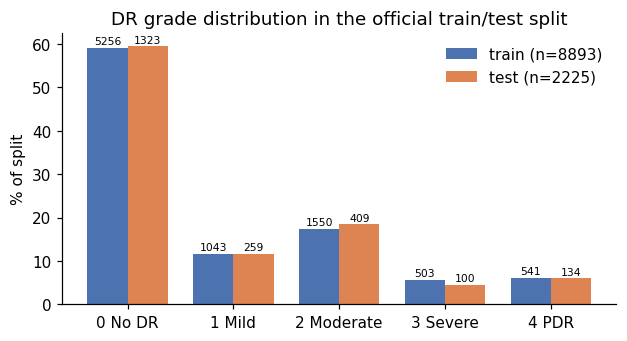

In [ ]:
ct = pd.crosstab(df.grade, df.split)[["train", "test"]]
pct = (ct / ct.sum() * 100).round(1)
table = pd.concat({"n": ct, "%": pct}, axis=1); table.index = GRADES
display(table)

chi2, p, *_ = stats.chi2_contingency(ct)
print(f"Grade distribution train vs test: chi2={chi2:.2f}, p={p:.3f}  (p>0.05 ⇒ split is stratified)")
print("Imbalance ratio (largest/smallest class):", round(ct.sum(1).max() / ct.sum(1).min(), 1))
print("Referable DR (grade ≥2) prevalence: {:.1%}".format((df.grade >= 2).mean()))
print("Sight-threatening (grade ≥3) prevalence: {:.1%}".format((df.grade >= 3).mean()))

fig, ax = plt.subplots(figsize=(6.5, 3.2))
x = np.arange(5); w = 0.38
for j, (s, c) in enumerate([("train", "#4C72B0"), ("test", "#DD8452")]):
    b = ax.bar(x + (j - .5) * w, pct[s], w, label=f"{s} (n={ct[s].sum()})", color=c)
    ax.bar_label(b, labels=ct[s], fontsize=7, padding=1)
ax.set_xticks(x, GRADES); ax.set_ylabel("% of split"); ax.legend(frameon=False)
ax.set_title("DR grade distribution in the official train/test split")
save(fig, "01_grade_distribution")

##2 · Laterality (the only patient-level variable available)

In [ ]:
lat = pd.crosstab(df.grade, df.lr.map({0: "left", 1: "right"})); lat.index = GRADES
display(lat.assign(**{"% right": (lat["right"] / lat.sum(1) * 100).round(1)}))
chi2, p, *_ = stats.chi2_contingency(lat)
print(f"Laterality vs grade: chi2={chi2:.2f}, p={p:.3f}")
print("No patient ID, age, sex, ethnicity, camera or site ⇒ subgroup/bias auditing is limited to laterality.")

lr,left,right,% right
0 No DR,3303,3276,49.8
1 Mild,671,631,48.5
2 Moderate,972,987,50.4
3 Severe,287,316,52.4
4 PDR,374,301,44.6


Laterality vs grade: chi2=9.92, p=0.042
No patient ID, age, sex, ethnicity, camera or site ⇒ subgroup/bias auditing is limited to laterality.


## 3 · Lesion labels: prevalence, co-occurrence and consistency with the grading criteria

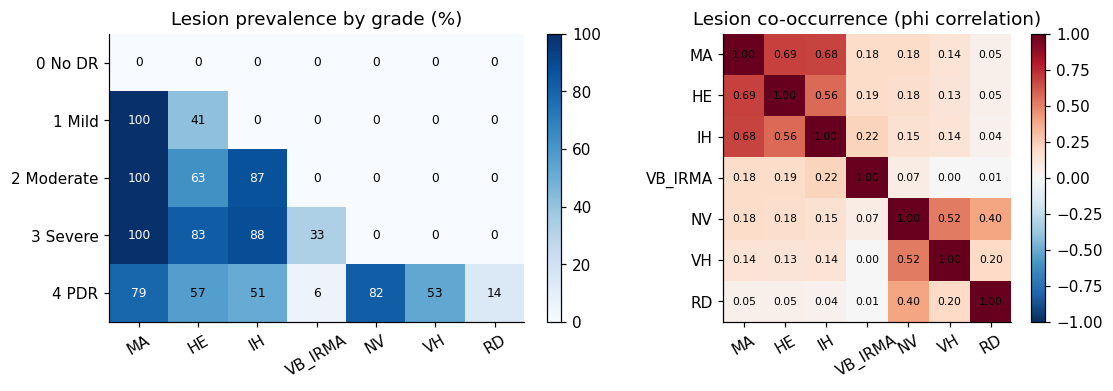

,images with lesion
Microaneurysm,4398
Hard exudate,2648
Intraretinal haemorrhage,2580
VB / IRMA,236
Neovascularisation,556
Vitreous haemorrhage,358
Retinal detachment,93


In [ ]:
prev = df.groupby("grade")[LES].mean() * 100
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw={"width_ratios": [1.15, 1]})
im = axes[0].imshow(prev.values, cmap="Blues", vmin=0, vmax=100, aspect="auto")
for (i, j), v in np.ndenumerate(prev.values):
    axes[0].text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8, color="white" if v > 60 else "black")
axes[0].set_xticks(range(7), LES, rotation=30); axes[0].set_yticks(range(5), GRADES)
axes[0].set_title("Lesion prevalence by grade (%)"); fig.colorbar(im, ax=axes[0], fraction=.04)

corr = np.corrcoef(L.T)
im2 = axes[1].imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
for (i, j), v in np.ndenumerate(corr):
    axes[1].text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7)
axes[1].set_xticks(range(7), LES, rotation=30); axes[1].set_yticks(range(7), LES)
axes[1].set_title("Lesion co-occurrence (phi correlation)"); fig.colorbar(im2, ax=axes[1], fraction=.04)
save(fig, "02_lesions_by_grade")
display(df[LES].sum().rename(dict(zip(LES, LES_FULL))).to_frame("images with lesion"))

In [ ]:
# Consistency with the paper's stated criteria (ICDR-style):
#   0 = no lesions; 1 = MA only; 2 = MA/IH/HE beyond mild; 3 = 4-2-1 rule (VB/IRMA or severe IH);
#   4 = NV, VH or RD present.
pdr = df[["NV", "VH", "RD"]].max(1) == 1
rules = {
    "R1  grade 0 with any lesion":              (df.grade == 0) & (df.n_lesions > 0),
    "R2  grade ≥1 with no lesion":              (df.grade >= 1) & (df.n_lesions == 0),
    "R3  grade 1 with lesion other than MA":    (df.grade == 1) & (L[:, 1:].sum(1) > 0),
    "R4  grade 1 without MA":                   (df.grade == 1) & (df.MA == 0),
    "R5  grade <4 with NV/VH/RD":               (df.grade < 4) & pdr,
    "R6  grade 4 without NV/VH/RD":             (df.grade == 4) & ~pdr,
    "R7  grade <3 with VB/IRMA":                (df.grade < 3) & (df.VB_IRMA == 1),
}
denom = {"R1": df.grade == 0, "R2": df.grade >= 1, "R3": df.grade == 1, "R4": df.grade == 1,
         "R5": df.grade < 4, "R6": df.grade == 4, "R7": df.grade < 3}
audit = pd.DataFrame({"n": {k: int(v.sum()) for k, v in rules.items()},
                      "% of relevant grades": {k: round(100 * v.sum() / max(1, denom[k[:2]].sum()), 1) for k, v in rules.items()}})
display(audit)

flag = np.zeros(len(df), bool)
for v in rules.values(): flag |= v.values
df["label_flag"] = flag
print("Grade-1 images that contain hard exudate:", int(((df.grade == 1) & (df.HE == 1)).sum()),
      f"({((df.grade == 1) & (df.HE == 1)).sum() / (df.grade == 1).sum():.1%} of Mild)")
print("Combinations of lesions seen in Mild:"); display(df[df.grade == 1][LES].value_counts().head(5))

,n,% of relevant grades
R1 grade 0 with any lesion,0,0.0
R2 grade ≥1 with no lesion,0,0.0
R3 grade 1 with lesion other than MA,537,41.2
R4 grade 1 without MA,0,0.0
R5 grade <4 with NV/VH/RD,0,0.0
R6 grade 4 without NV/VH/RD,0,0.0
R7 grade <3 with VB/IRMA,0,0.0


Grade-1 images that contain hard exudate: 537 (41.2% of Mild)
Combinations of lesions seen in Mild:


MA  HE  IH  VB_IRMA  NV  VH  RD
1   0   0   0        0   0   0     765
    1   0   0        0   0   0     537
Name: count, dtype: int64

##4 · Image properties

In [ ]:
def props(rel):
    p = f"{ROOT}/{rel}"
    W, H = Image.open(p).size
    img = cv2.imread(p, cv2.IMREAD_REDUCED_COLOR_4)
    g = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    fov = g > 15                                               # retina vs black background
    gi = g[fov] if fov.any() else g.ravel()
    lap = cv2.Laplacian(g, cv2.CV_64F)[cv2.erode(fov.astype(np.uint8), np.ones((9, 9))) > 0]
    b, gch, r = [img[..., c][fov].mean() if fov.any() else 0 for c in range(3)]
    return dict(width=W, height=H, filesize_kb=os.path.getsize(p) / 1024,
                fov_fraction=fov.mean(), brightness=gi.mean(), contrast=gi.std(),
                sharpness=lap.var() if lap.size else 0.0, mean_R=r, mean_G=gch, mean_B=b,
                dark_frac=(gi < 40).mean(), sat_frac=(gi > 245).mean())

cache = f"{OUT_DIR}/cfp_image_properties.csv"
if os.path.exists(cache):
    P = pd.read_csv(cache)
else:
    from concurrent.futures import ThreadPoolExecutor
    with ThreadPoolExecutor(8) as ex: P = pd.DataFrame(list(ex.map(props, df.image)))
    P.insert(0, "image", df.image.values); P.to_csv(cache, index=False)
df = df.merge(P, on="image")
df["aspect"] = df.width / df.height
PROPS = ["width", "aspect", "filesize_kb", "fov_fraction", "brightness", "contrast", "sharpness"]
display(df[PROPS].describe().T.round(2))
print("Distinct resolutions:", df.groupby(["width", "height"]).ngroups,
      "| non-square (|aspect-1|>0.02):", int((abs(df.aspect - 1) > .02).sum()))

,count,mean,std,min,25%,50%,75%,max
width,11118.0,1875.56,472.19,660.00,1571.00,1659.00,2290.00,3353.00
aspect,11118.0,1.02,0.06,0.97,1.00,1.00,1.00,1.33
filesize_kb,11118.0,670.34,400.09,65.67,392.23,554.32,852.42,2677.55
fov_fraction,11118.0,0.80,0.04,0.25,0.78,0.78,0.79,1.00
brightness,11118.0,97.48,32.05,26.22,74.95,94.36,113.94,209.88
contrast,11118.0,25.74,11.71,5.62,17.61,22.95,30.93,84.23
sharpness,11118.0,54.60,40.26,3.41,27.08,42.31,69.14,468.05


Distinct resolutions: 1857 | non-square (|aspect-1|>0.02): 1290


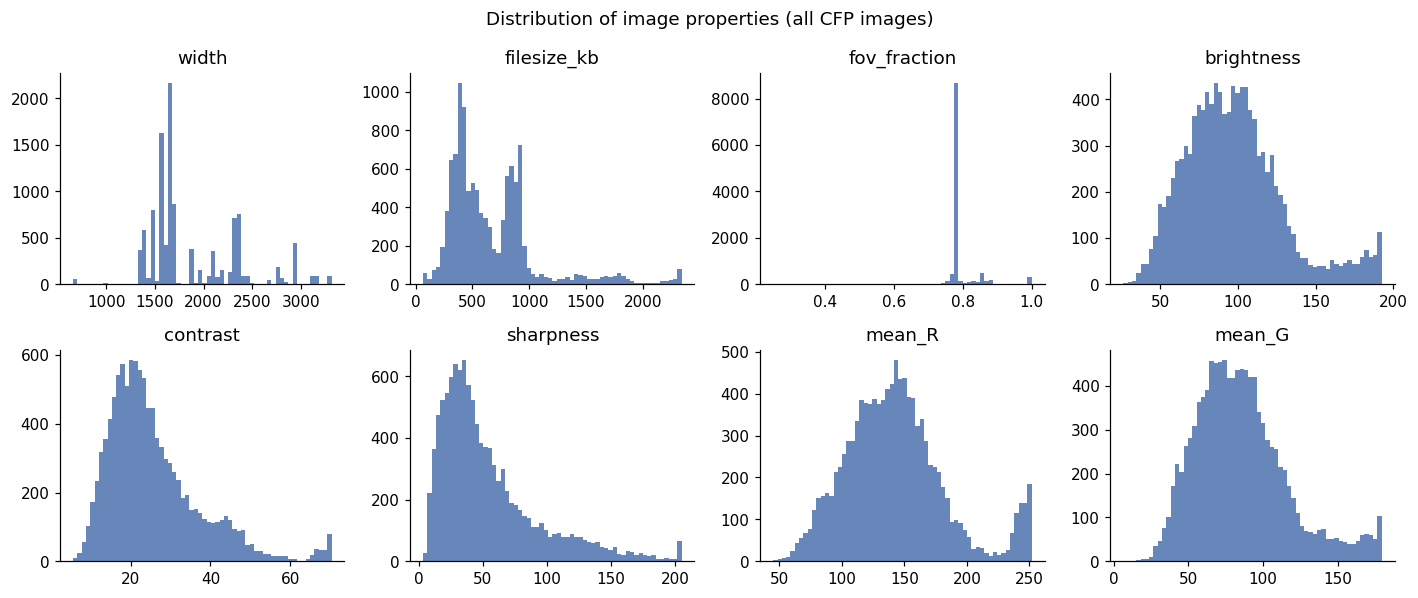

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(13, 5.5)); axes = axes.ravel()
for ax, c in zip(axes, ["width", "filesize_kb", "fov_fraction", "brightness", "contrast", "sharpness", "mean_R", "mean_G"]):
    data = df[c].clip(upper=df[c].quantile(.995))
    ax.hist(data, bins=60, color="#4C72B0", alpha=.85); ax.set_title(c)
fig.suptitle("Distribution of image properties (all CFP images)"); fig.tight_layout()
save(fig, "03_image_properties")

#5 · Do image properties differ by grade?

,spearman_rho_vs_grade,p,KS_train_vs_test,KS_p
property,,,,
width,-0.088,2.0e-20,0.021,0.433
aspect,0.033,4.4e-04,0.015,0.815
filesize_kb,-0.205,2.2e-105,0.012,0.962
fov_fraction,-0.052,3.7e-08,0.014,0.857
brightness,0.024,1.0e-02,0.029,0.089
contrast,0.027,4.6e-03,0.033,0.039
sharpness,-0.227,2.2e-129,0.014,0.884
mean_R,-0.053,2.0e-08,0.032,0.055
mean_G,0.074,7.3e-15,0.028,0.126


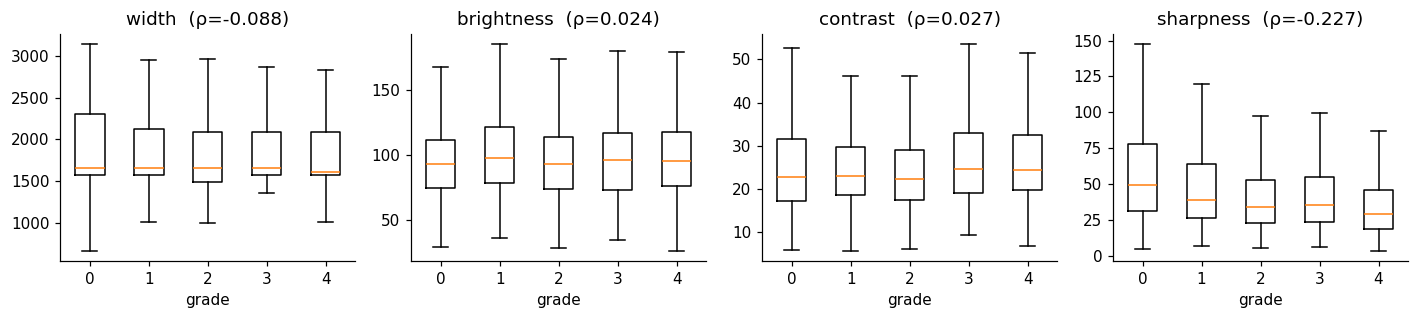

In [ ]:
rows = []
for c in PROPS + ["mean_R", "mean_G", "mean_B", "dark_frac"]:
    rho, p = stats.spearmanr(df[c], df.grade)
    ks, pks = stats.ks_2samp(df.loc[df.split == "train", c], df.loc[df.split == "test", c])
    rows.append(dict(property=c, spearman_rho_vs_grade=round(rho, 3), p=f"{p:.1e}",
                     KS_train_vs_test=round(ks, 3), KS_p=round(pks, 3)))
assoc = pd.DataFrame(rows).set_index("property"); display(assoc)

fig, axes = plt.subplots(1, 4, figsize=(13, 3))
for ax, c in zip(axes, ["width", "brightness", "contrast", "sharpness"]):
    ax.boxplot([df.loc[df.grade == g, c].clip(upper=df[c].quantile(.99)) for g in range(5)],
               showfliers=False)
    ax.set_xticks(range(1, 6), [g.split()[0] for g in GRADES])
    ax.set_title(f"{c}  (ρ={assoc.loc[c, 'spearman_rho_vs_grade']})"); ax.set_xlabel("grade")
fig.tight_layout(); save(fig, "04_properties_by_grade")

##6 · Exact and near-duplicate images (leakage audit)

In [ ]:
df["md5"] = [hashlib.md5(open(f"{ROOT}/{p}", "rb").read()).hexdigest() for p in df.image]
ex = df[df.duplicated("md5", keep=False)]; gx = ex.groupby("md5")
print("exact (byte-identical) duplicates:", len(ex), "images in", gx.ngroups, "groups")
print("exact groups spanning train AND test:", int((gx.split.nunique() > 1).sum()),
      "| with conflicting grades:", int((gx.grade.nunique() > 1).sum()))

exact (byte-identical) duplicates: 197 images in 97 groups
exact groups spanning train AND test: 34 | with conflicting grades: 0


exact md5 duplicate pairs found by vessel similarity: 104 | min similarity of exact pairs: 1.0


exact      cross_split       grade_conflict      
                size  sum        size   sum           size   sum
band                                                            
(0.8, 0.85]    11246    0       11246  3596          11246  8387
(0.85, 0.9]     9643    0        9643  3133           9643  7214
(0.9, 0.95]     3667    0        3667  1301           3667  2709
(0.95, 0.98]     125    0         125    51            125    89
(0.98, 0.995]     17    0          17     6             17     4
(0.995, 1.01]    131  104         131    48            131     0

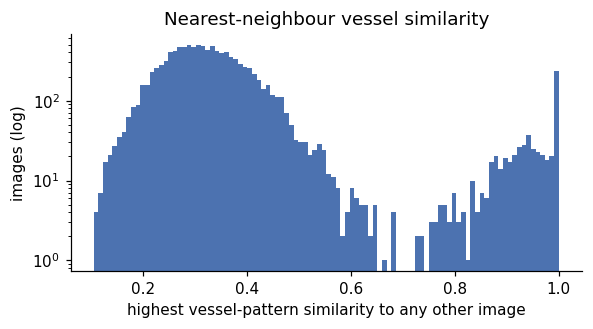

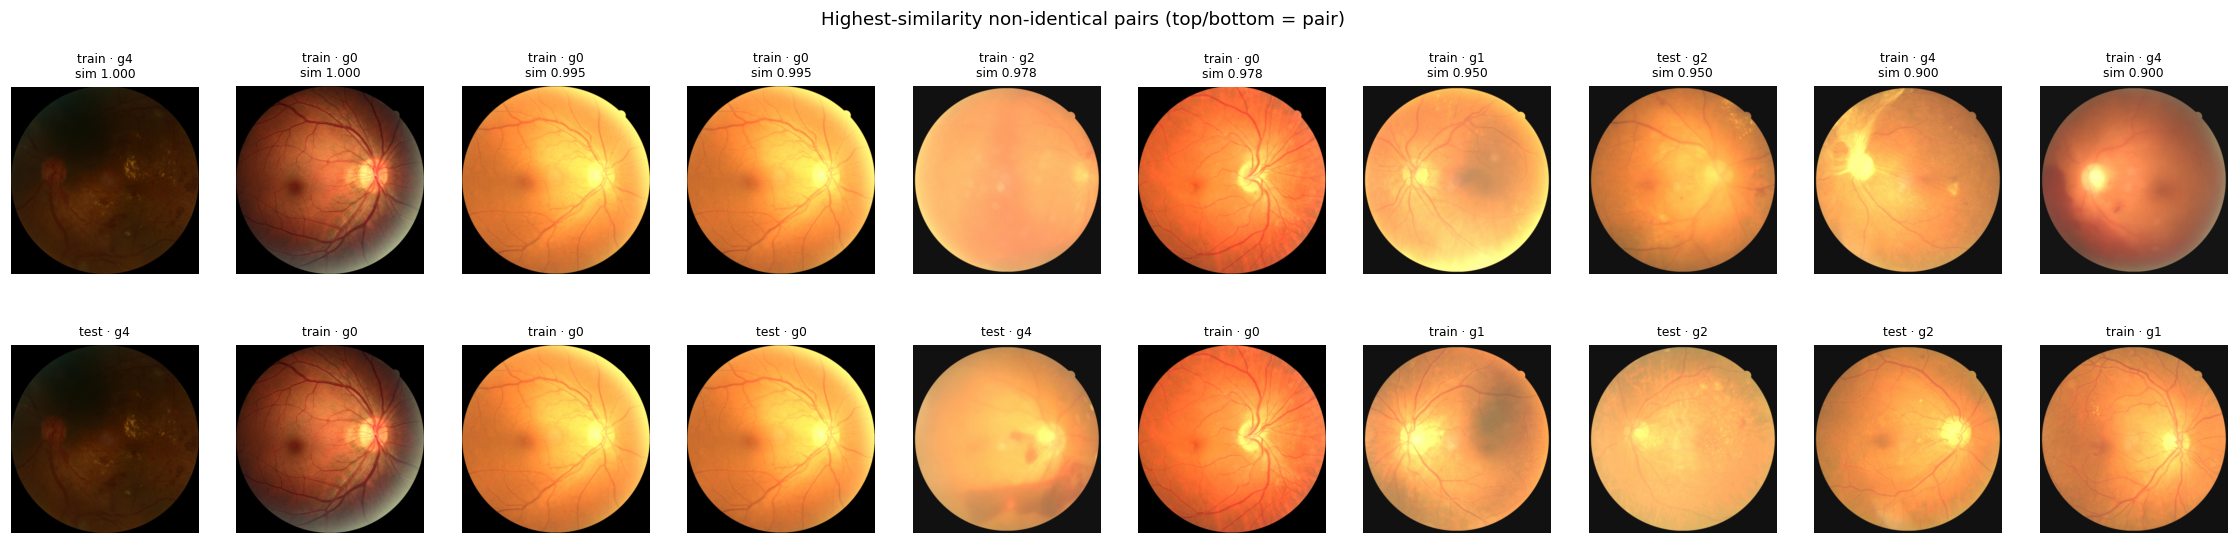

In [ ]:
#  Near-duplicate detection on retinal vessel structure

def vessel_vec(rel, size=96):
    im = cv2.imread(f"{ROOT}/{rel}", cv2.IMREAD_REDUCED_COLOR_4)
    h, w = im.shape[:2]; m = max(h, w)
    sq = np.zeros((m, m), np.float32)
    sq[(m - h) // 2:(m - h) // 2 + h, (m - w) // 2:(m - w) // 2 + w] = im[..., 1]   # green channel: best vessel contrast
    g = cv2.resize(sq, (256, 256), interpolation=cv2.INTER_AREA)
    fov = cv2.erode((g > 15).astype(np.uint8), np.ones((15, 15), np.uint8)).astype(bool)
    hp = g - cv2.GaussianBlur(g, (0, 0), 6)                                      # remove illumination, keep vessels
    hp[~fov] = 0
    v = cv2.resize(hp, (size, size), interpolation=cv2.INTER_AREA).ravel()
    v -= v.mean(); return (v / (np.linalg.norm(v) + 1e-8)).astype(np.float32)

from concurrent.futures import ThreadPoolExecutor
with ThreadPoolExecutor(8) as ex: X = np.stack(list(ex.map(vessel_vec, df.image)))

try:
    import torch; dev = "cuda" if torch.cuda.is_available() else "cpu"
    Xt = torch.from_numpy(X).to(dev)
    def sims(a, b): return (Xt[a:b] @ Xt.T).cpu().numpy()
except ImportError:
    def sims(a, b): return X[a:b] @ X.T

LOW = 0.80
rows, best = [], np.zeros(len(X), np.float32)
for a in range(0, len(X), 1024):
    Smat = sims(a, a + 1024)
    for r in range(Smat.shape[0]): Smat[r, a + r] = -1
    best[a:a + Smat.shape[0]] = Smat.max(1)
    ii, jj = np.nonzero(Smat > LOW)
    for i, j in zip(ii + a, jj):
        if i < j: rows.append((i, j, float(Smat[i - a, j])))
vp = pd.DataFrame(rows, columns=["i", "j", "sim"])
vp["exact"] = df.md5.values[vp.i] == df.md5.values[vp.j]
vp["cross_split"] = df.split.values[vp.i] != df.split.values[vp.j]
vp["grade_conflict"] = df.grade.values[vp.i] != df.grade.values[vp.j]

# sanity check: every known exact (md5) duplicate pair must score ≈ 1.0
md5_pairs = df[df.duplicated("md5", keep=False)].groupby("md5").size()
print("exact md5 duplicate pairs found by vessel similarity:", int(vp.exact.sum()),
      "| min similarity of exact pairs:", round(vp.loc[vp.exact, "sim"].min(), 4) if vp.exact.any() else None)

bins = [0.80, 0.85, 0.90, 0.95, 0.98, 0.995, 1.01]
vp["band"] = pd.cut(vp.sim, bins)
display(vp.groupby("band")[["exact", "cross_split", "grade_conflict"]].agg(["size", "sum"]))

fig, ax = plt.subplots(figsize=(6, 2.8))
ax.hist(best, bins=100, color="#4C72B0"); ax.set_yscale("log")
ax.set_xlabel("highest vessel-pattern similarity to any other image"); ax.set_ylabel("images (log)")
ax.set_title("Nearest-neighbour vessel similarity")
save(fig, "05a_vessel_similarity_hist")

# visual check: two non-exact pairs per band, so the threshold is chosen by eye, not assumed
show = vp[~vp.exact].sort_values("sim", ascending=False).groupby("band", observed=True).head(2)
show = show.sort_values("sim", ascending=False).head(10)
if len(show):
    fig, axes = plt.subplots(2, len(show), figsize=(2.6 * len(show), 5.6), squeeze=False)
    for k, (_, r) in enumerate(show.iterrows()):
        for row, idx in enumerate([r.i, r.j]):
            axes[row, k].imshow(cv2.cvtColor(cv2.imread(f"{ROOT}/{df.image[idx]}", cv2.IMREAD_REDUCED_COLOR_4), cv2.COLOR_BGR2RGB))
            axes[row, k].set_title(f"{df.split[idx]} · g{df.grade[idx]}" + (f"\nsim {r.sim:.3f}" if row == 0 else ""), fontsize=8)
            axes[row, k].axis("off")
    fig.suptitle("Highest-similarity non-identical pairs (top/bottom = pair)"); save(fig, "05b_vessel_near_duplicates")

In [ ]:
p = df.grade.value_counts(normalize=True); base = 1 - (p**2).sum()
print(f"grade-conflict rate for random pairs: {base:.1%}")
print(vp[~vp.exact].groupby("band", observed=True).grade_conflict.mean().round(3))

grade-conflict rate for random pairs: 59.8%
band
(0.8, 0.85]      0.746
(0.85, 0.9]      0.748
(0.9, 0.95]      0.739
(0.95, 0.98]     0.712
(0.98, 0.995]    0.235
(0.995, 1.01]    0.000
Name: grade_conflict, dtype: float64


In [ ]:
# final duplicate groups (exact md5 + vessel similarity ≥ TAU)
TAU = 0.98     # set from the histogram gap and the visual check above (empirical, documented)
parent = list(range(len(df)))
def find(a):
    while parent[a] != a: parent[a] = parent[parent[a]]; a = parent[a]
    return a
for _, grp in df.groupby("md5").indices.items():
    for k in grp[1:]: parent[find(k)] = find(grp[0])
for i, j in vp.loc[vp.sim >= TAU, ["i", "j"]].values: parent[find(int(i))] = find(int(j))
df["dup_group"] = [find(i) for i in range(len(df))]
g = df.groupby("dup_group"); size = g.image.transform("size")
cross = g.split.transform("nunique") > 1
print("images in a duplicate group:", int((size > 1).sum()), "| groups:", int((g.size() > 1).sum()))
print("groups spanning train AND test:", int((g.split.nunique() > 1).sum()))
print("groups with conflicting grades:", int((g.grade.nunique() > 1).sum()))
print("test images with a copy in train:", int(((df.split == "test") & cross).sum()))
print("train images to drop (copy of a test image):", int(((df.split == "train") & cross).sum()))

images in a duplicate group: 263 | groups: 127
groups spanning train AND test: 45
groups with conflicting grades: 4
test images with a copy in train: 46
train images to drop (copy of a test image): 52


##7 · Visual inspection: typical images per grade and lowest-quality images

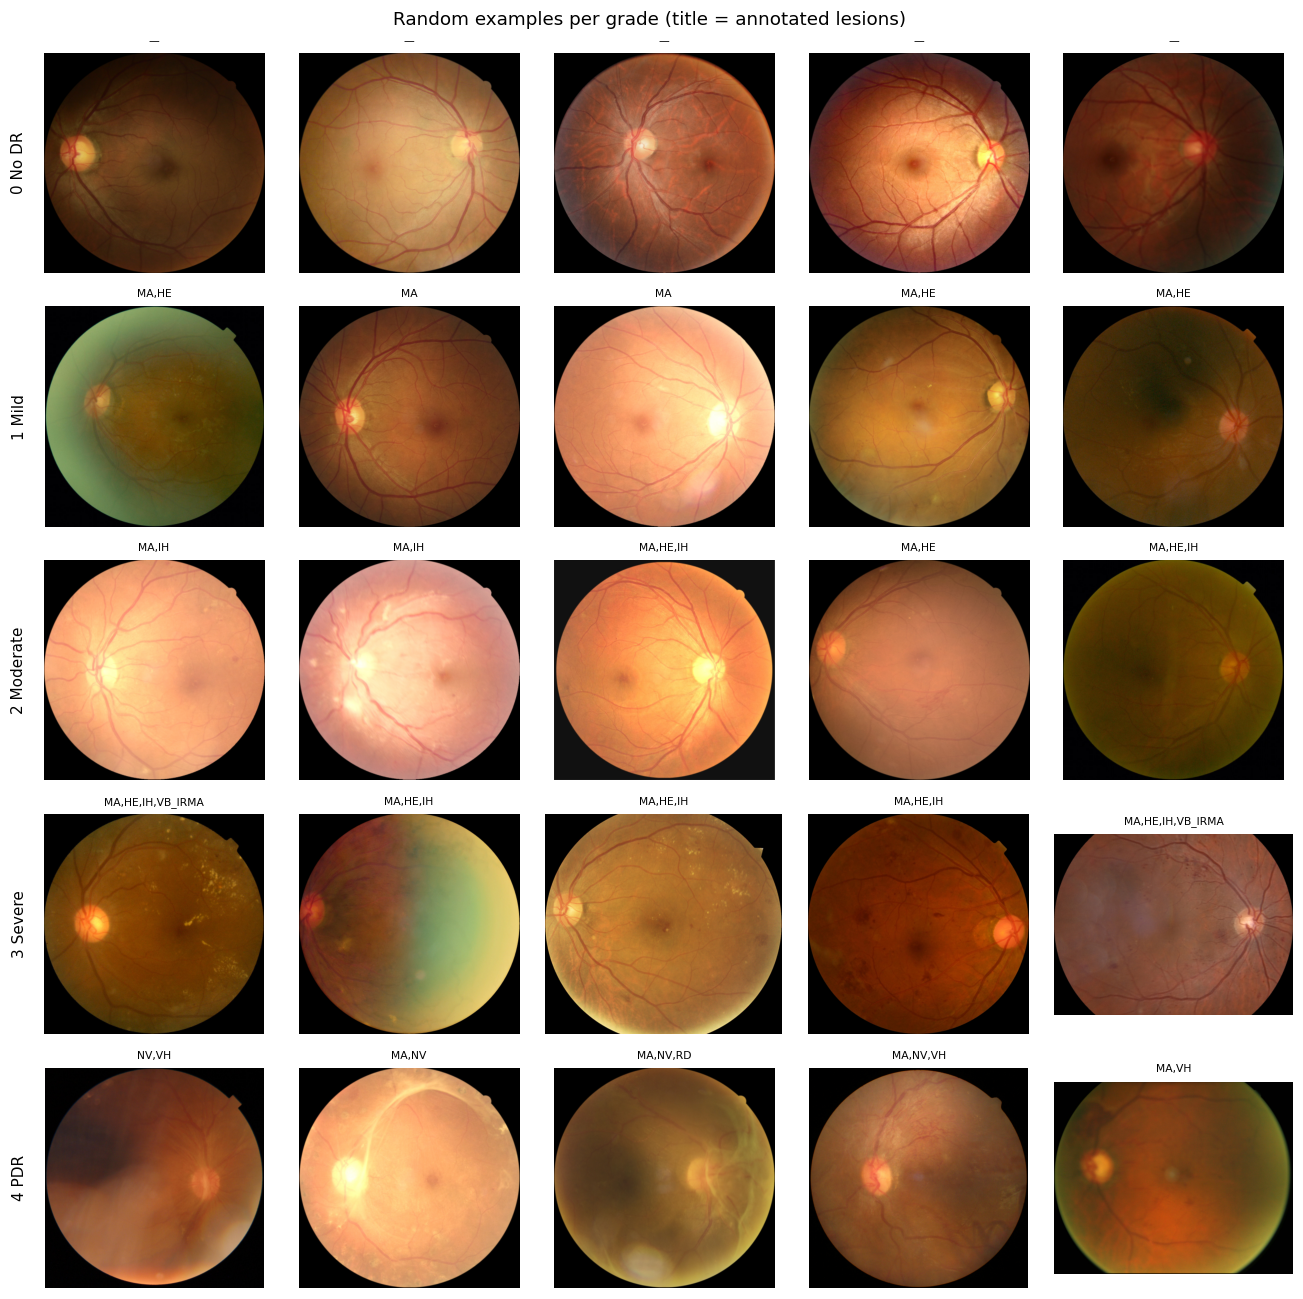

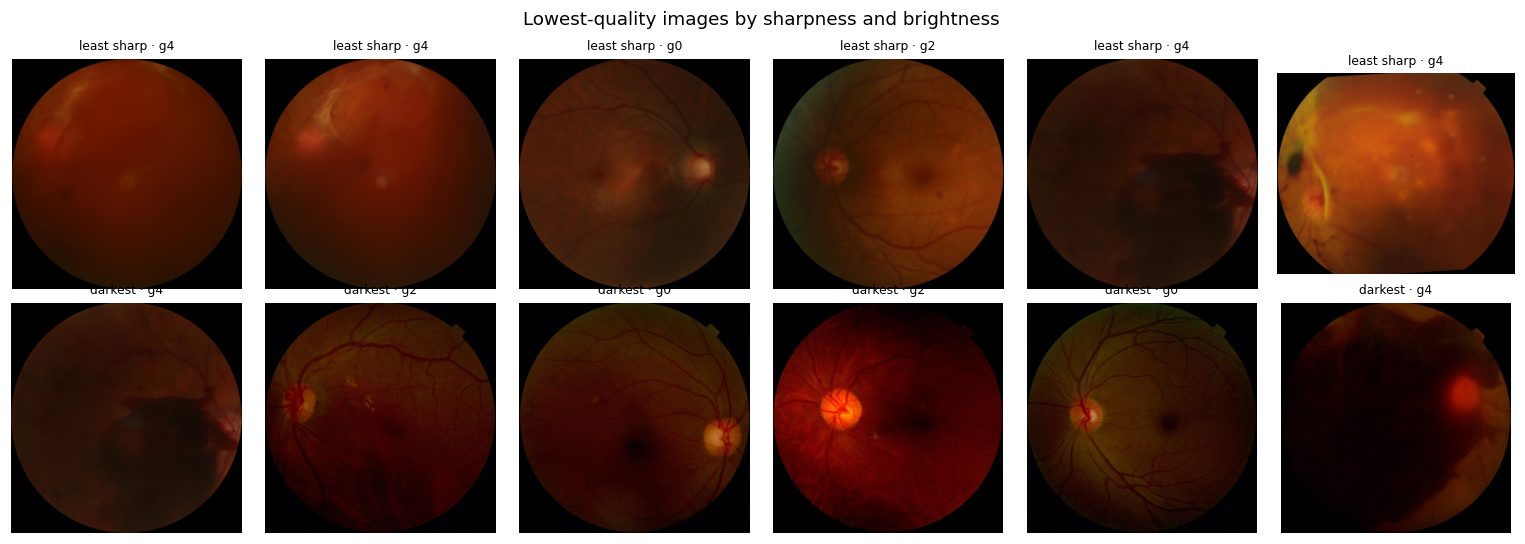

In [ ]:
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(5, 5, figsize=(12, 12))
for g_ in range(5):
    idx = rng.choice(df.index[df.grade == g_], 5, replace=False)
    for k, i in enumerate(idx):
        ax = axes[g_, k]
        ax.imshow(cv2.cvtColor(cv2.imread(f"{ROOT}/{df.image[i]}", cv2.IMREAD_REDUCED_COLOR_4), cv2.COLOR_BGR2RGB))
        les = ",".join(l for l in LES if df.at[i, l]) or "—"; ax.set_title(les, fontsize=7); ax.axis("off")
    axes[g_, 0].text(-0.08, .5, GRADES[g_], transform=axes[g_, 0].transAxes, rotation=90, va="center", ha="right", fontsize=10)
fig.suptitle("Random examples per grade (title = annotated lesions)"); fig.tight_layout(); save(fig, "06_examples_per_grade")

fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for row, (col, asc, lab) in enumerate([("sharpness", True, "least sharp"), ("brightness", True, "darkest")]):
    for k, i in enumerate(df.sort_values(col, ascending=asc).index[:6]):
        axes[row, k].imshow(cv2.cvtColor(cv2.imread(f"{ROOT}/{df.image[i]}", cv2.IMREAD_REDUCED_COLOR_4), cv2.COLOR_BGR2RGB))
        axes[row, k].set_title(f"{lab} · g{df.grade[i]}", fontsize=8); axes[row, k].axis("off")
fig.suptitle("Lowest-quality images by sharpness and brightness"); fig.tight_layout(); save(fig, "07_low_quality_examples")

#8 Final Preprocessing

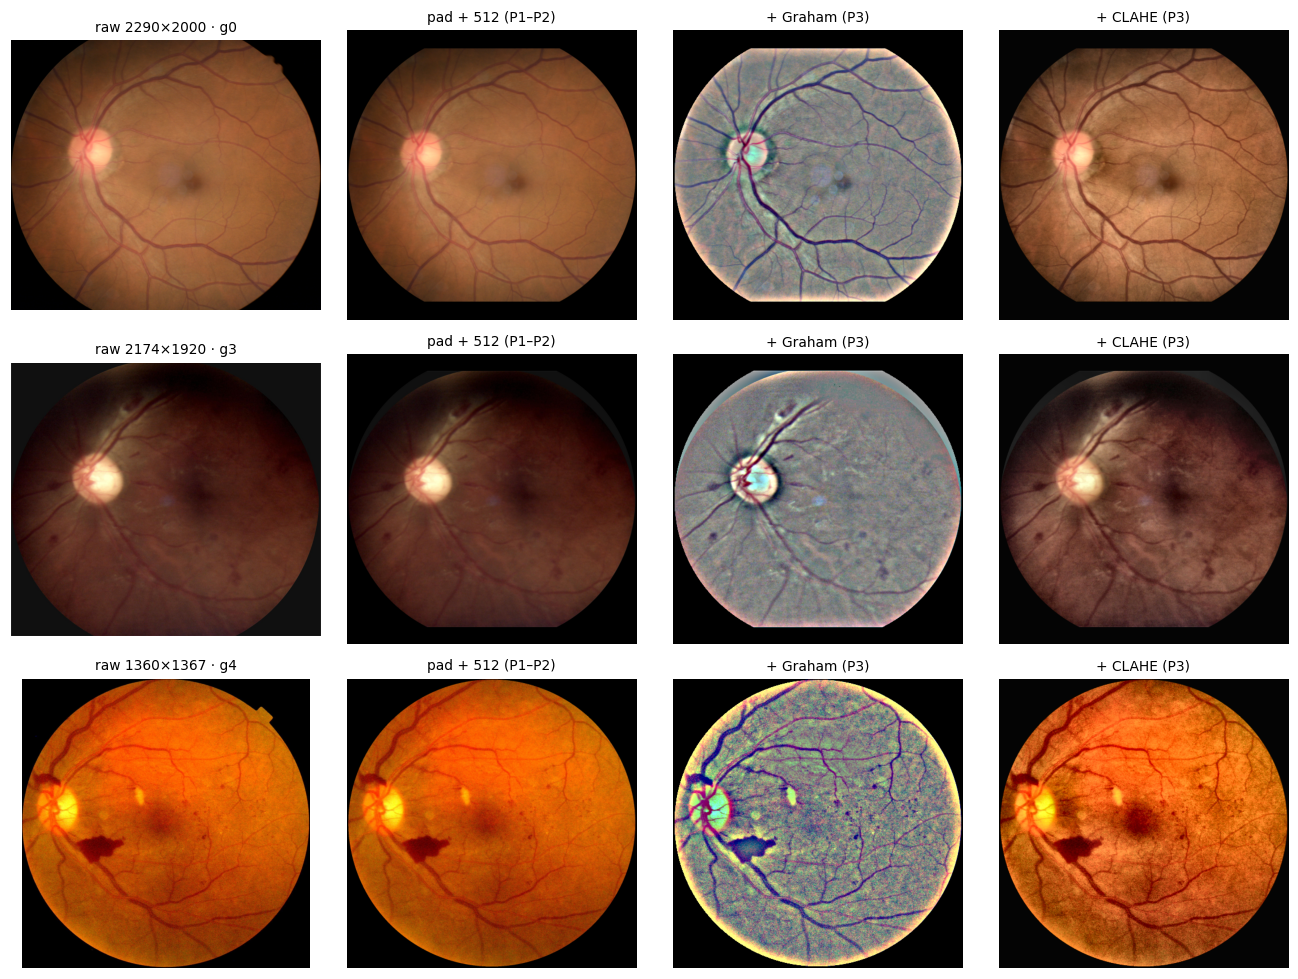

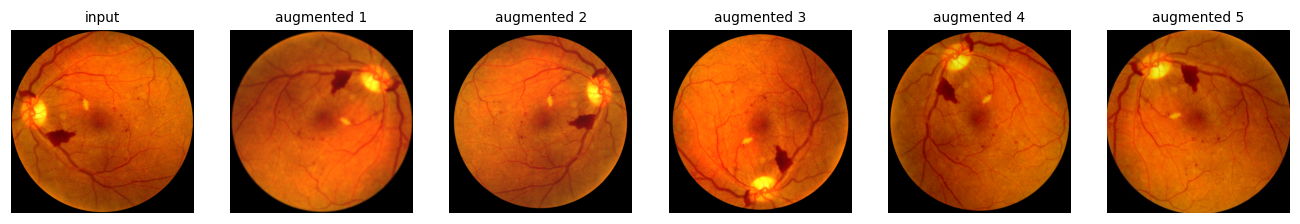

In [ ]:
#final preprocessing + candidate normalisations + augmentation preview
def pad_square(img):
    h, w = img.shape[:2]; s = max(h, w)
    out = np.zeros((s, s, 3), img.dtype)
    out[(s - h) // 2:(s - h) // 2 + h, (s - w) // 2:(s - w) // 2 + w] = img
    return out

def preprocess(img, size=512):
    img = img.copy(); img[~fov_mask(img)] = 0
    return cv2.resize(pad_square(img), (size, size), interpolation=cv2.INTER_AREA)

def fov_mask(img, shrink=0.99):

    h, w = img.shape[:2]
    yy, xx = np.ogrid[:h, :w]
    r = shrink * max(h, w) / 2
    return (xx - (w - 1) / 2) ** 2 + (yy - (h - 1) / 2) ** 2 <= r ** 2


def graham(img, sigma=10):
    out = cv2.addWeighted(img, 4, cv2.GaussianBlur(img, (0, 0), sigma), -4, 128)
    out[~(fov_mask(img) & (img.max(2) > 0))] = 0; return out
def clahe_lab(img):
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
    lab[..., 0] = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(lab[..., 0])
    return cv2.cvtColor(lab, cv2.COLOR_LAB2BGR)

rng = np.random.default_rng(SEED)
nonsq = df.index[abs(df.aspect - 1) > .1]
if len(nonsq) == 0: nonsq = df.index
picks = [rng.choice(nonsq),
         df.sort_values("brightness").index[len(df) // 50],
         rng.choice(df.index[df.grade == 4])]
fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for r, i in enumerate(picks):
    raw = cv2.imread(f"{ROOT}/{df.image[i]}"); base = preprocess(raw)
    for c, (t, im) in enumerate([(f"raw {raw.shape[1]}×{raw.shape[0]} · g{df.grade[i]}", raw),
                                 ("pad + 512 (P1–P2)", base), ("+ Graham (P3)", graham(base)), ("+ CLAHE (P3)", clahe_lab(base))]):
        axes[r, c].imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)); axes[r, c].set_title(t, fontsize=9); axes[r, c].axis("off")
fig.tight_layout(); save(fig, "08_preprocessing_options")

# augmentation preview (P4–P6). the same transforms are implemented in the training code
def augment(img, r):
    mask = fov_mask(img)
    out = img.astype(np.float32)
    out = out * r.uniform(.8, 1.2) + r.uniform(-20, 20)
    out = 255 * (np.clip(out, 0, 255) / 255) ** r.uniform(.8, 1.25)
    out = np.clip(out, 0, 255).astype(np.uint8); out[~mask] = 0
    if r.random() < .3: out = cv2.GaussianBlur(out, (0, 0), r.uniform(.5, 1.5))
    if r.random() < .3:
        _, enc = cv2.imencode(".jpg", out, [cv2.IMWRITE_JPEG_QUALITY, int(r.integers(40, 90))]); out = cv2.imdecode(enc, 1)
    if r.random() < .5: out = out[:, ::-1]
    M = cv2.getRotationMatrix2D((256, 256), r.uniform(-180, 180), r.uniform(.95, 1.05))
    return cv2.warpAffine(np.ascontiguousarray(out), M, (512, 512))
base = preprocess(cv2.imread(f"{ROOT}/{df.image[picks[2]]}"))
fig, axes = plt.subplots(1, 6, figsize=(15, 2.8))
axes[0].imshow(cv2.cvtColor(base, cv2.COLOR_BGR2RGB)); axes[0].set_title("input", fontsize=9)
for k in range(1, 6):
    axes[k].imshow(cv2.cvtColor(augment(base, rng), cv2.COLOR_BGR2RGB)); axes[k].set_title(f"augmented {k}", fontsize=9)
for a in axes: a.axis("off")
save(fig, "09_augmentation_preview")

##9- summary

In [ ]:
g = df.groupby("dup_group")
cross = g.split.transform("nunique") > 1
summary = {
    "n_images": len(df), "n_train": int((df.split == "train").sum()), "n_test": int((df.split == "test").sum()),
    "class_counts": df.grade.value_counts().sort_index().to_dict(),
    "imbalance_ratio": round(df.grade.value_counts().max() / df.grade.value_counts().min(), 2),
    "label_rule_violations": audit["n"].to_dict(),
    "mild_with_hard_exudate": int(((df.grade == 1) & (df.HE == 1)).sum()),
    "dup_vessel_similarity_threshold": TAU,
    "images_in_dup_groups": int(g.grade.transform("size").gt(1).sum()),
    "dup_groups_cross_split": int((g.split.nunique() > 1).sum()),
    "dup_groups_grade_conflict": int((g.grade.nunique() > 1).sum()),
    "test_images_with_copy_in_train": int(((df.split == "test") & cross).sum()),
    "train_images_to_drop": int(((df.split == "train") & cross).sum()),
    "max_abs_spearman_property_vs_grade": assoc["spearman_rho_vs_grade"].abs().max(),
}
print(json.dumps(summary, indent=2, default=int))
json.dump(summary, open(f"{OUT_DIR}/eda_summary.json", "w"), indent=2, default=int)
keep = ["image", "split", "grade", "lr"] + LES + ["n_lesions", "label_flag", "md5", "dup_group"] + PROPS + ["dark_frac"]
df[keep].to_csv(f"{OUT_DIR}/cfp_eda.csv", index=False)
print("saved:", f"{OUT_DIR}/cfp_eda.csv")

{
  "n_images": 11118,
  "n_train": 8893,
  "n_test": 2225,
  "class_counts": {
    "0": 6579,
    "1": 1302,
    "2": 1959,
    "3": 603,
    "4": 675
  },
  "imbalance_ratio": 10.91,
  "label_rule_violations": {
    "R1  grade 0 with any lesion": 0,
    "R2  grade \u22651 with no lesion": 0,
    "R3  grade 1 with lesion other than MA": 537,
    "R4  grade 1 without MA": 0,
    "R5  grade <4 with NV/VH/RD": 0,
    "R6  grade 4 without NV/VH/RD": 0,
    "R7  grade <3 with VB/IRMA": 0
  },
  "mild_with_hard_exudate": 537,
  "dup_vessel_similarity_threshold": 0.98,
  "images_in_dup_groups": 263,
  "dup_groups_cross_split": 45,
  "dup_groups_grade_conflict": 4,
  "test_images_with_copy_in_train": 46,
  "train_images_to_drop": 52,
  "max_abs_spearman_property_vs_grade": 0.227
}
saved: /content/drive/MyDrive/mmrdr/eda/cfp_eda.csv
